In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = pd.read_csv("/Users/caitlinbrogden/Desktop/DATA150/tables_V2.0/Ad_table (extra).csv")


In [6]:
X.head()

,Maker,Genmodel,Genmodel_ID,Adv_ID,Adv_year,Adv_month,Color,Reg_year,Bodytype,Runned_Miles,...,Engine_power,Annual_Tax,Wheelbase,Height,Width,Length,Average_mpg,Top_speed,Seat_num,Door_num
0,Bentley,Arnage,10_1,10_1$$1,2018,4,Silver,2000.0,Saloon,60000,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0
1,Bentley,Arnage,10_1,10_1$$2,2018,6,Grey,2002.0,Saloon,44000,...,450.0,315,3116.0,1515.0,2125.0,5390.0,13.7 mpg,179 mph,5.0,4.0
2,Bentley,Arnage,10_1,10_1$$3,2017,11,Blue,2002.0,Saloon,55000,...,400.0,315,3116.0,1515.0,2125.0,5390.0,14.7 mpg,155 mph,5.0,4.0
3,Bentley,Arnage,10_1,10_1$$4,2018,4,Green,2003.0,Saloon,14000,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0
4,Bentley,Arnage,10_1,10_1$$5,2017,11,Grey,2003.0,Saloon,61652,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0


In [7]:
print(X.dtypes)

Maker            object
 Genmodel        object
 Genmodel_ID     object
Adv_ID           object
Adv_year          int64
Adv_month         int64
Color            object
Reg_year        float64
Bodytype         object
Runned_Miles     object
Engin_size       object
Gearbox          object
Fuel_type        object
Price           float64
Engine_power    float64
Annual_Tax       object
Wheelbase       float64
Height          float64
Width           float64
Length          float64
Average_mpg      object
Top_speed        object
Seat_num        float64
Door_num        float64
dtype: object


In [8]:
X['Runned_Miles'] = pd.to_numeric(X['Runned_Miles'], errors='coerce')
X['Price'] = pd.to_numeric(X['Price'], errors='coerce')

X = X.dropna(subset=['Runned_Miles', 'Price'])
X = X[(X['Runned_Miles'] > 0) & (X['Price'] > 0)]

Q1 = X[['Runned_Miles', 'Price']].quantile(0.25)
Q3 = X[['Runned_Miles', 'Price']].quantile(0.75)
IQR = Q3 - Q1

X = X[~((X[['Runned_Miles', 'Price']] < (Q1 - 1.5 * IQR)) | 
          (X[['Runned_Miles', 'Price']] > (Q3 + 1.5 * IQR))).any(axis=1)]

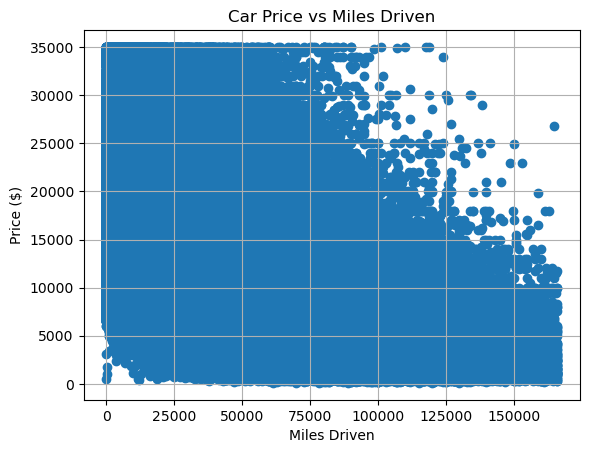

In [9]:
X['Runned_Miles'] = X['Runned_Miles'].astype(str)
X['Runned_Miles'] = X['Runned_Miles'].str.extract(r'(\d+\.?\d*)').astype(float)

X = X.sort_values(by='Runned_Miles')

plt.scatter(X['Runned_Miles'], X['Price'])

plt.title("Car Price vs Miles Driven")
plt.xlabel("Miles Driven")
plt.ylabel("Price ($)")

plt.grid(True)
plt.show()

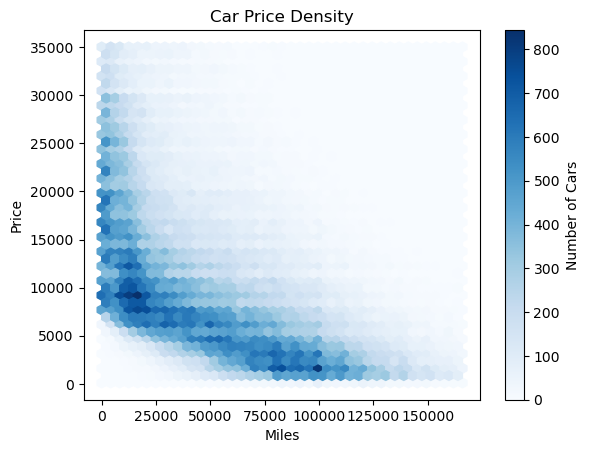

In [10]:
plt.hexbin(X['Runned_Miles'], X['Price'], gridsize=40, cmap='Blues')
plt.colorbar(label='Number of Cars')
plt.xlabel("Miles")
plt.ylabel("Price")
plt.title("Car Price Density")
plt.show()

/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/4123602920.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_price = X.groupby('mile_bin')['Price'].mean()


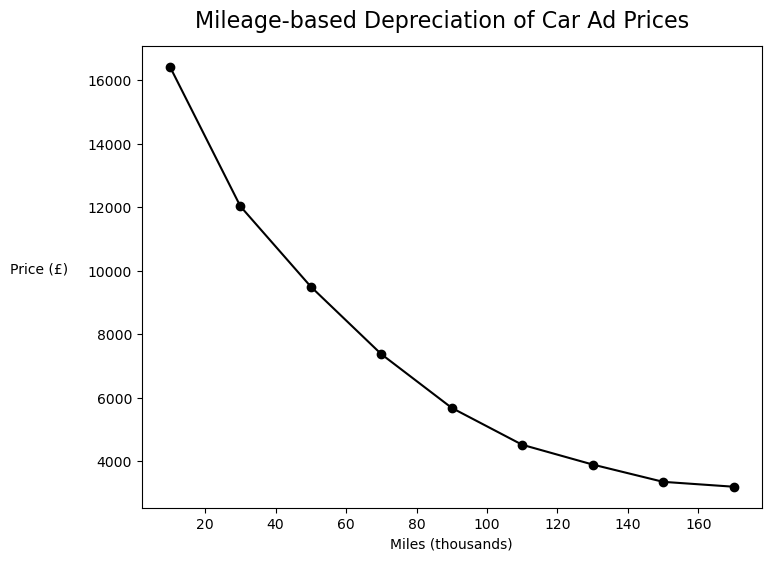

In [11]:
bins = range(0, int(X['Runned_Miles'].max()) + 20000, 20000)

X['mile_bin'] = pd.cut(X['Runned_Miles'], bins=bins)

avg_price = X.groupby('mile_bin')['Price'].mean()

bin_centers = [interval.mid for interval in avg_price.index]

bin_centers_k = [x/1000 for x in bin_centers]

plt.figure(figsize=(8,6))

plt.plot(bin_centers_k, avg_price.values, marker='o', color='black')

plt.suptitle("Mileage-based Depreciation of Car Ad Prices", fontsize=16, y=0.94)

plt.xlabel("Miles (thousands)")
plt.ylabel("Price (£)", rotation=0, labelpad=35)
plt.show()

In [12]:
print(X['Maker'].unique())

['Toyota' 'Subaru' 'Vauxhall' 'Citroen' 'Suzuki' 'Ssangyong' 'Volkswagen'
 'Peugeot' 'SEAT' 'Fiat' 'Mitsubishi' 'Nissan' 'Abarth' 'BMW' 'Hyundai'
 'Mazda' 'Honda' 'Dacia' 'MG' 'DS' 'Lexus' 'Ford' 'Kia' 'Volvo' 'SKODA'
 'Renault' 'Audi' 'Alfa Romeo' 'Mercedes-Benz' 'Infiniti' 'Jeep' 'Isuzu'
 'Land Rover' 'Zenos' 'Smart' 'Jaguar' 'MEV' 'Ginetta' 'Sebring' 'MINI'
 'Westfield' 'Chevrolet' 'Pilgrim' 'Ferrari' 'Maserati' 'Brooke'
 'Chrysler' 'Tiger' 'Caterham' 'Porsche' 'Raw' 'Rover' 'Hummer'
 'Great Wall' 'Cadillac' 'Saab' 'Grinnall' 'Bentley' 'Dodge' 'Reva'
 'Proton' 'Daewoo' 'TVR' 'Morgan' 'Lincoln' 'Lotus' 'Daihatsu' 'Corvette'
 'London Taxis International' 'Aston Martin' 'Santana' 'Perodua' 'Jensen'
 'Tesla' 'Daimler' 'Opel' 'Rolls-Royce']


In [13]:
print(X['Fuel_type'].unique())

['Diesel' 'Petrol' 'Bi Fuel' nan 'Hybrid  Petrol/Electric' 'Electric'
 'Hybrid  Petrol/Electric Plug-in' 'Petrol Hybrid' 'Petrol Plug-in Hybrid'
 'Hybrid  Diesel/Electric Plug-in' 'Diesel Hybrid'
 'Hybrid  Diesel/Electric' 'Diesel Plug-in Hybrid' 'Petrol Ethanol']


/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/3784468579.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot = X_clean.groupby(['mile_bin', 'Luxury_Tier'])['Price'].mean().unstack()
/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/3784468579.py:53: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Reds', 4)


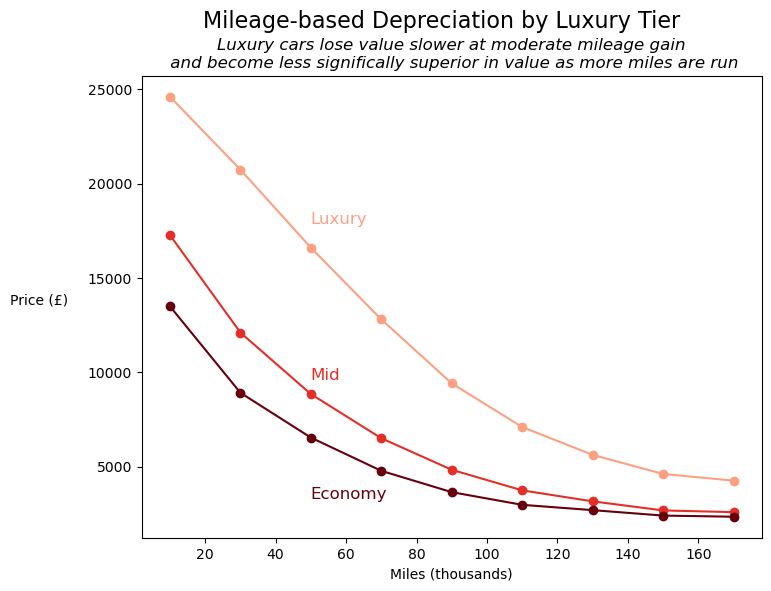

In [14]:
import matplotlib.cm as cm
exclude_brands = [
    'Caterham', 'Zenos', 'Ginetta', 'Westfield', 'MEV', 'Pilgrim',
    'Raw', 'Tiger', 'Brooke', 'Grinnall', 'Sebring',
    'Morgan', 'TVR', 'Lotus'
]

X_clean = X[~X['Maker'].isin(exclude_brands)].copy()

luxury_map = {
    # Economy
    'Dacia': 'Economy', 'Renault': 'Economy', 'Peugeot': 'Economy',
    'Citroen': 'Economy', 'Fiat': 'Economy', 'Vauxhall': 'Economy',
    'Opel': 'Economy', 'Hyundai': 'Economy', 'Kia': 'Economy',
    'MG': 'Economy', 'Suzuki': 'Economy', 'Nissan': 'Economy',
    'Toyota': 'Economy', 'Honda': 'Economy', 'Mazda': 'Economy',
    'Mitsubishi': 'Economy', 'Daihatsu': 'Economy',
    'Proton': 'Economy', 'Perodua': 'Economy', 'Daewoo': 'Economy',
    'Skoda': 'Economy', 'SEAT': 'Economy', 'Ssangyong': 'Economy',
    'Isuzu': 'Economy', 'Great Wall': 'Economy',

    # Mid
    'Volkswagen': 'Mid', 'Ford': 'Mid', 'Subaru': 'Mid',
    'MINI': 'Mid', 'Jeep': 'Mid', 'Smart': 'Mid',
    'Volvo': 'Mid', 'Chrysler': 'Mid', 'Dodge': 'Mid', 'Chevrolet': 'Mid',
    'Infiniti': 'Mid','Tesla': 'Mid', 'Lincoln': 'Mid','Lexus': 'Mid',

    # Luxury
    'Audi': 'Luxury', 'BMW': 'Luxury', 'Mercedes-Benz': 'Luxury',
    'Jaguar': 'Luxury', 'Land Rover': 'Luxury',
    'Porsche': 'Luxury', 'Maserati': 'Luxury',
    'Ferrari': 'Luxury', 'Bentley': 'Luxury', 'Rolls-Royce': 'Luxury',
    'Aston Martin': 'Luxury', 'Cadillac': 'Luxury', 'Saab': 'Luxury', 'Alfa Romeo': 'Luxury'
}

# Apply mapping
X_clean['Luxury_Tier'] = X_clean['Maker'].map(luxury_map)

# Optional: drop anything unmapped
X_clean = X_clean.dropna(subset=['Luxury_Tier'])


bins = range(0, int(X_clean['Runned_Miles'].max()) + 20000, 20000)
X_clean['mile_bin'] = pd.cut(X_clean['Runned_Miles'], bins=bins)



pivot = X_clean.groupby(['mile_bin', 'Luxury_Tier'])['Price'].mean().unstack()

bin_centers = [interval.mid for interval in pivot.index]
bin_centers_k = [x / 1000 for x in bin_centers]

cmap = cm.get_cmap('Reds', 4)

tier_order = ['Luxury','Mid','Economy']

plt.figure(figsize=(8,6))

label_idx = len(bin_centers_k) // 4

for i, tier in enumerate(tier_order):
    if tier in pivot.columns:
        plt.plot(
            bin_centers_k,
            pivot[tier],
            marker='o',
            label=tier,
            color=cmap(i+1)  # skip very light color
        )
        offset = { 'Luxury': 1500, 'Mid': 1000, 'Economy': -3000 }

        plt.text(
            bin_centers_k[label_idx],
            pivot[tier].iloc[label_idx] + offset.get(tier, 0),
            tier,
            color=cmap(i+1),
            fontsize=12,
            va='center'
        )




plt.suptitle("Mileage-based Depreciation by Luxury Tier", fontsize=16, y=0.99)
plt.title("Luxury cars lose value slower at moderate mileage gain\n and become less significally superior in value as more miles are run", fontsize=12, style='italic')

plt.xlabel("Miles (thousands)")
plt.ylabel("Price (£)", rotation=0, labelpad=35)
plt.show()



In [15]:
(Z['Fuel_type'] == 'Electric').sum()

NameError: name 'Z' is not defined

/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/4050781608.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = Z_clean.groupby(['mile_bin2', 'Fuel_Cats'])['Price'].transform('count')
/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/4050781608.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot2 = Z_clean.groupby(['mile_bin2', 'Fuel_Cats'])['Price'].mean().unstack()
/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/4050781608.py:56: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. U

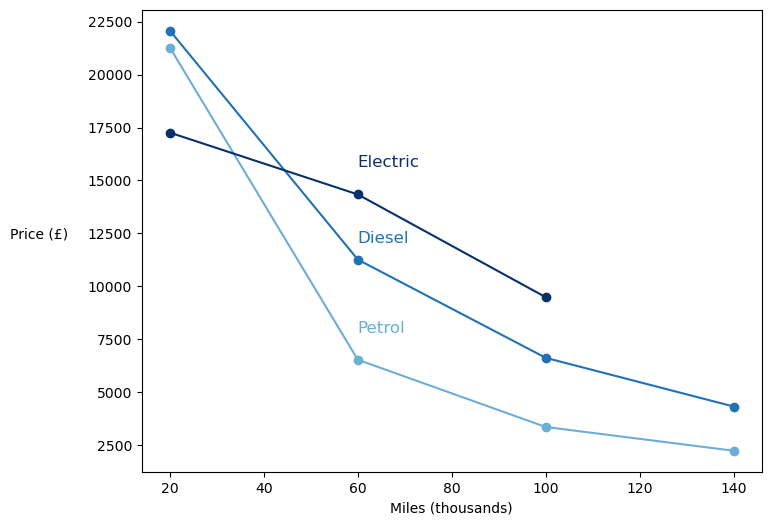

In [16]:

fuel_map = {
    # PETROL
    'Petrol': 'Petrol',
    'Petrol Plug-in Hybrid': 'Petrol',
    'Petrol Ethanol': 'Petrol',
    'Hybrid Petrol/Electric Plug-in': 'Petrol',
    'Hybrid Petrol/Electric': 'Petrol',
    'Petrol Hybrid': 'Petrol',
    'Bi Fuel': 'Petrol',

    # DIESEL
    'Diesel': 'Diesel',
    'Diesel Hybrid': 'Diesel',
    'Diesel Plug-in Hybrid': 'Diesel',
    'Hybrid Diesel/Electric': 'Diesel',
    'Hybrid Diesel/Electric Plug-in': 'Diesel',

    # ELECTRIC
    'Electric': 'Electric'
}

Z = pd.read_csv("/Users/caitlinbrogden/Desktop/DATA150/tables_V2.0/Ad_table (extra).csv")

Z_clean = Z.copy()

Z_clean['Runned_Miles'] = pd.to_numeric(Z_clean['Runned_Miles'], errors='coerce')

Z_clean['Fuel_Cats'] = Z_clean['Fuel_type'].map(fuel_map)

Z_clean = Z_clean.dropna(subset=['Fuel_Cats', 'Runned_Miles', 'Price'])

threshold = Z_clean['Runned_Miles'].quantile(0.99)
Z_clean = Z_clean[Z_clean['Runned_Miles'] <= threshold]

max_miles = Z_clean['Runned_Miles'].max()

if pd.isna(max_miles):
    raise ValueError("No valid Runned_Miles values after cleaning")

max_miles = int(max_miles)

bins2 = range(0, int(max_miles) + 40000, 40000)
#bins2 = range(0, max_miles + 20000, 20000)


Z_clean['mile_bin2'] = pd.cut(Z_clean['Runned_Miles'], bins=bins2)

counts = Z_clean.groupby(['mile_bin2', 'Fuel_Cats'])['Price'].transform('count')
#Z_clean = Z_clean[counts >= 12]

pivot2 = Z_clean.groupby(['mile_bin2', 'Fuel_Cats'])['Price'].mean().unstack()

bin_centers = [interval.mid for interval in pivot2.index]
bin_centers_k = [x / 1000 for x in bin_centers]

cmap = cm.get_cmap('Blues', 5)

tier_order = ['Petrol','Diesel','Electric']

plt.figure(figsize=(8,6))

label_idx = len(bin_centers_k) // 4
for i, tier in enumerate(tier_order):
    if tier in pivot2.columns:
        plt.plot(
            bin_centers_k,
            pivot2[tier],
            marker='o',
            label=tier,
            color=cmap(i+2)  # skip very light color
        )
        offset = {'Petrol': 1500, 'Diesel': 1000, 'Electric': 1500}

        plt.text(
            bin_centers_k[label_idx],
            pivot2[tier].iloc[label_idx] + offset.get(tier, 0),
            tier,
            color=cmap(i+2),
            fontsize=12,
            va='center'
        )


plt.xlabel("Miles (thousands)")
plt.ylabel("Price (£)", rotation=0, labelpad=35)
plt.show()



/var/folders/m2/vk5rwh414_73wwh3y6y0n97w0000gn/T/ipykernel_73846/4100918702.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot = Z_clean.groupby(['mile_bin', 'Color'])['Price'].mean().unstack()


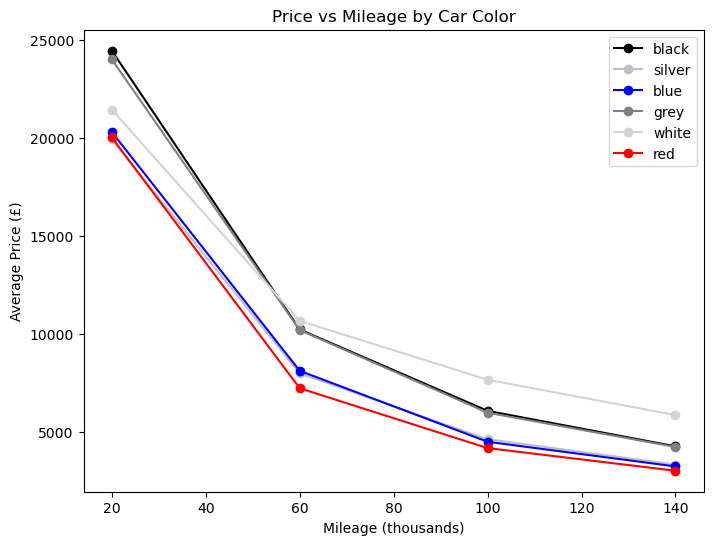

In [17]:

Z_clean = Z.copy()

# Clean color
Z_clean['Color'] = (
    Z_clean['Color']
    .astype(str)
    .str.strip()
    .str.lower()
)

Z_clean['Color'] = Z_clean['Color'].replace({
    'navy': 'blue'
})

main_colors = ['black', 'silver', 'blue', 'grey', 'white', 'red']

Z_clean = Z_clean[Z_clean['Color'].isin(main_colors)]


Z_clean['Runned_Miles'] = pd.to_numeric(Z_clean['Runned_Miles'], errors='coerce')
Z_clean = Z_clean.dropna(subset=['Runned_Miles', 'Price'])


threshold = Z_clean['Runned_Miles'].quantile(0.99)
Z_clean = Z_clean[Z_clean['Runned_Miles'] <= threshold]

max_miles = Z_clean['Runned_Miles'].max()
bins = range(0, int(max_miles) + 40000, 40000)

Z_clean['mile_bin'] = pd.cut(Z_clean['Runned_Miles'], bins=bins)

pivot = Z_clean.groupby(['mile_bin', 'Color'])['Price'].mean().unstack()

# Plot
color_order = ['black', 'silver', 'blue', 'grey', 'white', 'red']

color_map = {
    'black': 'black',
    'silver': 'silver',
    'blue': 'blue',
    'grey': 'grey',
    'white': 'lightgray',
    'red': 'red'
}

plt.figure(figsize=(8,6))

for color in color_order:
    if color in pivot.columns:
        plt.plot(
            [i.mid / 1000 for i in pivot.index],
            pivot[color],
            marker='o',
            label=color,
            color=color_map[color]
        )

plt.legend()
plt.grid(False)
plt.xlabel("Mileage (thousands)")
plt.ylabel("Average Price (£)")
plt.title("Price vs Mileage by Car Color")
plt.show()




In [18]:
print(Z['Color'].unique())

['Silver' 'Grey' 'Blue' 'Green' 'Black' nan 'White' 'Red' 'Brown' 'Orange'
 'Maroon' 'Purple' 'Yellow' 'Multicolour' 'Gold' 'Pink' 'Bronze' 'Beige'
 'Burgundy' 'Magenta' 'Turquoise' 'Indigo' 'Navy']


In [19]:
print(Z['Adv_year'].unique())

[2018 2017 2020 2021 2016 2015 2014 2019 2013 2012]


In [20]:
print(Z['Bodytype'].unique())

['Saloon' 'Convertible' 'SUV' 'Estate' 'Coupe' nan 'Hatchback' 'MPV'
 'Combi Van' 'Panel Van' 'Minibus' 'Window Van' 'Pickup' 'Manual'
 'Car Derived Van' 'Tipper' 'Camper' 'Chassis Cab' 'Limousine']
